<img src="./src/LogoUTNNegro.png" align="right" width="150">

#### Teoría de los Circuitos 2

# Trabajo Semanal 10
#### Renzo Villani

## Consignas

**Parte A:**  Diseñe el cuadripolo A para que se comporte como:

- filtro pasa bajos Chevy de 3er. orden
- no disipativo
- normalizado en frecuencia e impedancia

respetando la siguiente topología:
<center><img src="./src/img1_TS10.png"  width="500"></center>

1. Obtenga la impedancia de entrada al cuadripolo A, cargado con un resistor de 1Ω a la salida.
2. Sintetice **A** como un cuadripolo escalera.
3. Simule el comportamiento de la red en LTspice graficando $S_{21}$ y $S_{21}$ en función de la frecuencia. (Ver explicación de Agustín Alba Chicar **1h 48m**)
4. Explique el comportamiento de A a partir de los valores de $S_{11}$ en las siguientes frecuencias:
- centro de la banda de paso
- frecuencia de corte
- transición y centro de la banda de detenida
5. Modifique el circuito para que la frecuencia de corte sea 2 π 10⁶ rad/s y la resistencia del generador sea 50Ω.

***Parte B:*** Trabajo de Investigación sobre NANO VNA ( Vector Network Analyzer )
1. Explique brevemente la función principal de un VNA y en que situación/es puede ser fundamental tenerlo como herramienta de medición.
2. Comparar respecto a un *DSO GW Insteak* características de: Ancho de Banda, Rango Dinámico e Impedancia de Entrada.
3. Además de las mediciones de los parametros, ***investigar*** si el equipo cuenta con alguna medición en el dominio del tiempo.

## Parte A: Diseño de cuadripolo y parámetros S

### Punto 1 y 2

La transferencia de potencia se comporta como una función de aproximación Chebyshev pasabajos de 3er orden. Equivale al coeficiente de transducción $S_{21}$. Trabajo la expresión hasta obtenerla.

<center><img src="./src/img2_TS10.png"  width="800"></center>

Me valgo de un script para obtener facilmente $S_{21}$ a partir de $|S_{21}|²$ (más que nada el denominador Q).

In [13]:
# Importo las librerías para trabajar de acá en adelante.

# Librerías externas NumPy, SciPy y Matplotlib
from scipy.signal import TransferFunction
from scipy import signal as sig
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

# Librería de TC2
from pytc2.sistemas_lineales import pzmap, GroupDelay, bodePlot, analyze_sys, tf2sos_analog

from pytc2.general import a_equal_b_latex_s, print_latex

TransferFunctionContinuous(
array([1.  , 0.  , 0.75, 0.  ]),
array([1.        , 0.59607164, 0.9276507 , 0.25      ]),
dt: None
)


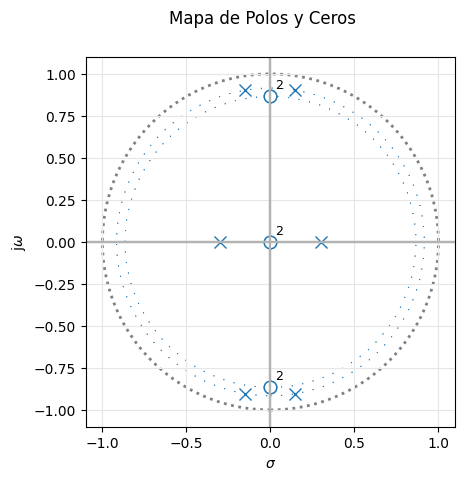

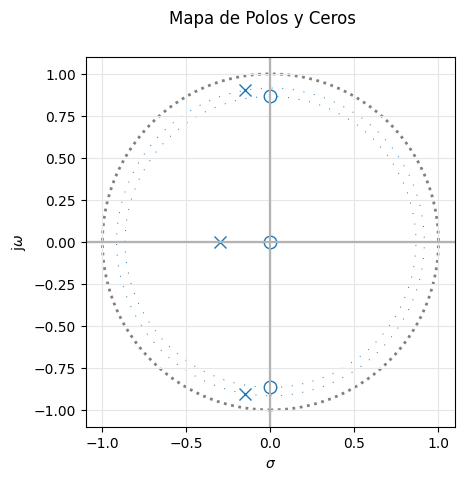

In [14]:
# Construyo |S11|²
numS11sq = np.array([1, 0, 3/2, 0, 9/16, 0, 0])
denS11sq = np.array([1, 0, 3/2, 0, 9/16, 0, -1/16])

TS11sq = TransferFunction(numS11sq , denS11sq)
pzmap(TS11sq)

# Construyo S11
Qroots = np.roots(denS11sq)
Qroots = Qroots[ np.real(Qroots) < 0 ]   # filtro los polos del semiplano derecho
denS11 = np.poly(Qroots)
numS11 = np.array([1, 0, 3/4, 0])   # numerador hardcodeado para que los ceros sean simples

TS11 = TransferFunction(numS11 , denS11)
pzmap(TS11)
print(TS11)

Una vez obtenido el parámetro $S_{21}$, calculo la impedancia de entrada y aplico Cauer para la síntesis pasiva.
<center><img src="./src/img3_TS10.png"  width="800"></center>

La impedancia de entrada termina siendo:
### <center>$Z_1(s) = \frac{s³+3/4*s}{s³+0.596*s²+0.928*s+0.25}$</center>

Valores de los componentes:
- $R_g=1$
- $R_L=1$
- $L_1=3.356$
- $L_2=3.356$
- $C=0.71$

### Punto 3

Pasa saber cómo simular los parámetros $S_{11}$ y $S_{21}$ tengo que primeros trabajarlos analíticamente a partir de sus definiciones.

<center><img src="./src/img4_TS10.png"  width="800"></center>

<center><img src="./src/img5_TS10.png"  width="800"></center>

Paso a simular circuitalmente en *LTspice* lo deducido.

<center><img src="./src/img6_TS10.png"  width="800"></center>

<center><img src="./src/img7_TS10.JPEG"  width="800"></center>

Los resultados de la simulación son los esperados.

<center><img src="./src/img8_TS10.jpeg"  width="400"></center>

### Punto 4

Sabemos que $S{11}$ es el **coeficiente de reflexión de la entrada del cuadripolo** $A$. El barrido frecuencial de esta condice con lo que queremos:

- En $f \approx 0.0219Hz$ estamos en el punto de máxima adaptación: $S_{11}$ tiende a 0 (no se refleja nada del puerto al generador) y $S_{21} \approx 1$ (se transfiere la máxima potencia disponible). Recordar que $|S_{11}|²+|S_{21}|²=1$

- Para $f \rightarrow \infty$ $S_{11}$ tiende a 1, se refleja toda la onda. Cosa que es lógica ya que el inductor para muy altas frecuencias se comporta como un circuito abierdo ($Z_L \rightarrow \infty$).

- Para $f \rightarrow \infty$ $S_{11}$ tiende a 0, se transmite toda la potencia. También es esperable ya que, en DC, el circuito termina siendo el generador con la carga conectada.

### Punto 5

Para cumplir con las caracteristicas pedidas simplemente tengo implementar una norma de frecuencia del valor pedido y una norma de impedancia con valor correspondiente a la resistencia del nuevo generador.
<center><img src="./src/img9_TS10.png"  width="800"></center>

## Parte B: Investigación NANO VNA

### Punto 1

Un VNA mide, en función de la frecuencia, la potencia reflejada y la transmitida por una red, y lo hace en módulo y fase. Mide $S_{11}$ y $S_{11}$, y de ahí calcula pérdidas de retorno e inserción, impedancia compleja y ROE. Es fundamental cuando hay que caracterizar o ajustar redes de RF: antenas (adaptación/ROE), filtros, amplificadores y cables.

### Punto 2

$$
\begin{array}{|l|c|c|}
\hline
 & \textbf{NanoVNA V2 Plus4} & \textbf{GDS-1000A-U series} \\ \hline
\text{Ancho de banda} & \text{50 kHz a 4,4 GHz} & \text{DC a 70/100/150 MHz} \\ \hline
\text{Rango dinámico} & \text{90 dB (1 GHz), 80 dB (3 GHz)} & \text{8 bits } (\approx 48\ \text{dB}) \\ \hline
\text{Impedancia de entrada} & 50\ \Omega & 1\ \text{M}\Omega,\ \sim 15\ \text{pF} \\ \hline
\end{array}
$$

El VNA es un instrumento de RF con puertos de $50\Omega$ y mucho mayor rango dinámico. El osciloscopio es de alta impedancia y mide tensión en el tiempo, con un ancho de banda mucho menor.

### Punto 3

El *NanoVNA V2* puede simular la reflectometría en el dominio del tiempo mediante la transformación de datos en el dominio de la frecuencia.

## Conclusión

Se diseñó un filtro pasabajos Chebyshev de 3er orden como cuadripolo LC sin pérdidas doblemente cargado, a partir de $|S_{21}|² = 1/(1+\epsilon²*C_3(ω))$ y de la relación $|S_{11}|²+|S_{21}|²=1$. Luego se obtuvo Z₁ y, mediante Cauer, se sintetizó como una escalera L–C–L. La simulación en LTspice confirmó la respuesta esperada. Al desnormalizar a $1 MHz$ y $50\Omega$, la respuesta se mantuvo con el eje de frecuencia desplazado.

En la investigación se vio que un VNA caracteriza redes de RF midiendo $S_{11}$ y $S_{21}$, y que a diferencia de un osciloscopio ofrece mayor ancho de banda, mayor rango dinámico y una entrada de $50\Omega$. Además, el NanoVNA incluye medición en el dominio del tiempo (TDR).